In [71]:
!apt-get update
!apt-get install tesseract-ocr
!pip install pytesseract opencv-python matplotlib

'apt-get' is not recognized as an internal or external command,
operable program or batch file.
'apt-get' is not recognized as an internal or external command,
operable program or batch file.


In [124]:
import cv2
import numpy as np
import pytesseract
import matplotlib.pyplot as plt
import difflib

# Load gambar asli (pastikan path gambar benar)
image_path = '03_Blurred(2).png' # atau 'image_0.png'
img_color = cv2.imread(image_path)
img_gray = cv2.cvtColor(img_color, cv2.COLOR_BGR2GRAY)

print("Pustaka diimpor dan gambar berhasil dimuat!")

Pustaka diimpor dan gambar berhasil dimuat!


In [125]:
def calculate_accuracy(gt, test):
    if len(gt) == 0:
        return 0, 0.0

    matcher = difflib.SequenceMatcher(None, gt, test)
    match_chars = sum([m.size for m in matcher.get_matching_blocks()])
    accuracy = (match_chars / len(gt)) * 100

    return match_chars, accuracy

print("Fungsi hitung akurasi siap digunakan.")

Fungsi hitung akurasi siap digunakan.


In [130]:
print("Silakan upload file citra ijazah:")

filename = "03_Blurred(2).png"

# Membaca gambar dan mengubah ke Grayscale
img_bgr = cv2.imread(filename)
img_gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)

# Rotasi 90 derajat searah jarum jam agar teks tidak terbaca vertikal
#img_gray = cv2.rotate(img_gray, cv2.ROTATE_90_CLOCKWISE)

print(f"File '{filename}' berhasil diproses (Grayscale).")

Silakan upload file citra ijazah:
File '03_Blurred(2).png' berhasil diproses (Grayscale).


In [131]:
import cv2
import numpy as np

# Foto asli tanpa crop dan tanpa rotasi
img_original = img_gray.copy()

# Dictionary untuk menyimpan hasil
processed_images = {}

# 1. Original
processed_images["Original"] = img_original.copy()

# 2. Mean Filter
processed_images["Mean Filter"] = cv2.blur(
    img_original, (5, 5)
)

# 3. Median Filter
processed_images["Median Filter"] = cv2.medianBlur(
    img_original, 5
)

# 4. Gaussian Filter
processed_images["Gaussian Filter"] = cv2.GaussianBlur(
    img_original, (5, 5), 0
)

# 5. Sharpening
kernel_sharp = np.array([
    [0, -1, 0],
    [-1, 5, -1],
    [0, -1, 0]
])

processed_images["Sharpening"] = cv2.filter2D(
    img_original,
    -1,
    kernel_sharp
)

print("Foto asli tidak di-crop dan tidak dirotasi.")
print("Semua metode filtering dan sharpening berhasil diterapkan.")

Foto asli tidak di-crop dan tidak dirotasi.
Semua metode filtering dan sharpening berhasil diterapkan.


In [132]:
# Teks kunci yang menjadi tolok ukur akurasi (Disesuaikan dengan potongan gambar)
ground_truth = "Nomor ijazah: 571012022000056"
total_gt_chars = len(ground_truth)

ocr_results = {}
print("Mulai mengekstrak teks dengan OCR...\n")

for name, img in processed_images.items():
    # Proses OCR
    text = pytesseract.image_to_string(img).strip()

    # Membersihkan jarak spasi/enter berlebih
    text_clean = " ".join(text.split())

    # Hitung akurasi
    match_chars, acc = calculate_accuracy(ground_truth, text_clean)

    ocr_results[name] = {
        "text": text_clean if text_clean != "" else "[Tidak ada teks terdeteksi]",
        "match_chars": match_chars,
        "accuracy": acc
    }
    print(f"OCR untuk '{name}' selesai.")

print("\nProses OCR selesai seluruhnya.")

Mulai mengekstrak teks dengan OCR...

OCR untuk 'Original' selesai.
OCR untuk 'Mean Filter' selesai.
OCR untuk 'Median Filter' selesai.
OCR untuk 'Gaussian Filter' selesai.
OCR untuk 'Sharpening' selesai.

Proses OCR selesai seluruhnya.


Metode          | Hasil OCR (Cuplikan 30 Karakter)    | Karakter Benar  | Akurasi   
Original        | Nomor ijazah: 571012022000056       | 29 dari 29      | 100.00%
Mean Filter     | Nomor ijazah: $710120220000S6       | 27 dari 29      | 93.10%
Median Filter   | Nomor ijazah: 571012022000056       | 29 dari 29      | 100.00%
Gaussian Filter | Nomor ijazah: 571012022000056       | 29 dari 29      | 100.00%
Sharpening      | Nomor ijazah: 571012022000056       | 29 dari 29      | 100.00%


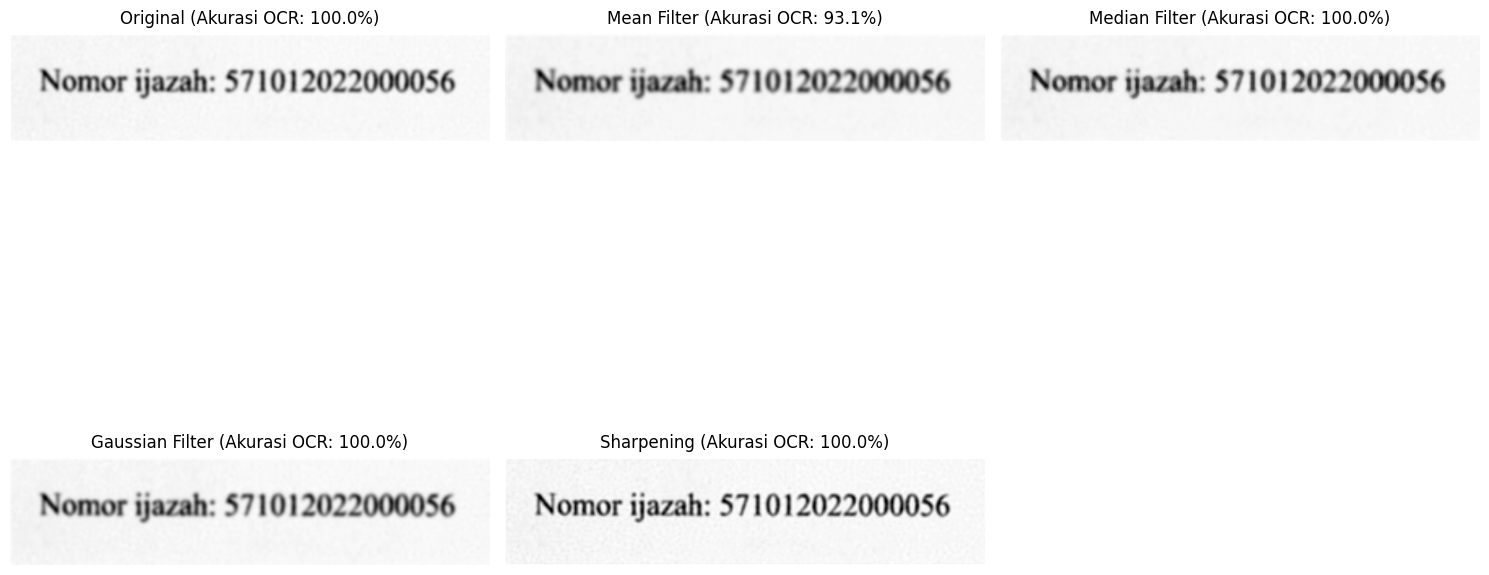

In [133]:
# --- TABEL HASIL ---
print("="*95)
print(f"{'Metode':<15} | {'Hasil OCR (Cuplikan 30 Karakter)':<35} | {'Karakter Benar':<15} | {'Akurasi':<10}")
print("="*95)

for name, result in ocr_results.items():
    snippet = result["text"][:30] + "..." if len(result["text"]) > 30 else result["text"]
    char_info = f"{result['match_chars']} dari {total_gt_chars}"
    print(f"{name:<15} | {snippet:<35} | {char_info:<15} | {result['accuracy']:.2f}%")
print("="*95)

# --- VISUALISASI ---
plt.figure(figsize=(15, 10))

for i, (name, img) in enumerate(processed_images.items()):
    plt.subplot(2, 3, i+1)
    plt.imshow(img, cmap='gray')
    plt.title(f"{name} (Akurasi OCR: {ocr_results[name]['accuracy']:.1f}%)")
    plt.axis('off')

plt.tight_layout()
plt.show()